# Homework 5: The LASSO and Boosting for Regression


Name: *Pratham Aggarwal* | Github: *prathamaeron* | USC ID: *1537722913*


## Communities and Crime Dataset


In [11]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.model_selection import cross_val_score, GridSearchCV, KFold
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
import xgboost as xgb

base_path = "../data"
names = []
with open(f"{base_path}/communities.names", "r", encoding="utf-8", errors="replace") as f:
    for line in f:
        if line.strip().startswith("@attribute "):
            name = line.strip()[len("@attribute "):].split()[0]
            names.append(name)

raw = pd.read_csv(
    f"{base_path}/communities.data",
    header=None,
    na_values="?",
    names=names,
)

print(f"Observations: {raw.shape[0]} | Features: {raw.shape[1]}")
print("Missing values by column:")
print(raw.isna().sum().sort_values(ascending=False).head(10).to_string())
print("First row: ")
display(raw.head(1))



Observations: 1994 | Features: 128
Missing values by column:
PolicReqPerOffic       1675
PolicAveOTWorked       1675
PolicPerPop            1675
RacialMatchCommPol     1675
PctPolicWhite          1675
PctPolicBlack          1675
PctPolicHisp           1675
PctPolicAsian          1675
PctPolicMinor          1675
OfficAssgnDrugUnits    1675
First row: 


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.9,0.12,...,0.12,0.26,0.2,0.06,0.04,0.9,0.5,0.32,0.14,0.2


In [12]:
nonpredictive = ["state", "county", "community", "communityname", "fold"]
target_name = "ViolentCrimesPerPop"

X = raw.drop(columns=[target_name] + nonpredictive)
y = raw[target_name]

X_train = X.iloc[:1495].copy()
y_train = y.iloc[:1495].copy()
X_test = X.iloc[1495:].copy()
y_test = y.iloc[1495:].copy()

imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

print(f"Training set: {X_train_imp.shape[0]} rows | {X_train_imp.shape[1]} features")
print(f"Test set: {X_test_imp.shape[0]} rows | {X_test_imp.shape[1]} features")
print(f"Missing values after imputation: {X_train_imp.isna().sum().sum() + X_test_imp.isna().sum().sum()}")
print("Top 10 training-set missing counts:")
print((X_train.isna().sum().sort_values(ascending=False).head(10)).to_string())



Training set: 1495 rows | 122 features
Test set: 499 rows | 122 features
Missing values after imputation: 0
Top 10 training-set missing counts:
PolicBudgPerPop         1256
PctPolicAsian           1256
LemasSwornFT            1256
LemasSwFTPerPop         1256
LemasSwFTFieldOps       1256
LemasSwFTFieldPerPop    1256
LemasTotalReq           1256
LemasTotReqPerPop       1256
PolicPerPop             1256
RacialMatchCommPol      1256


## (c) Correlation matrix

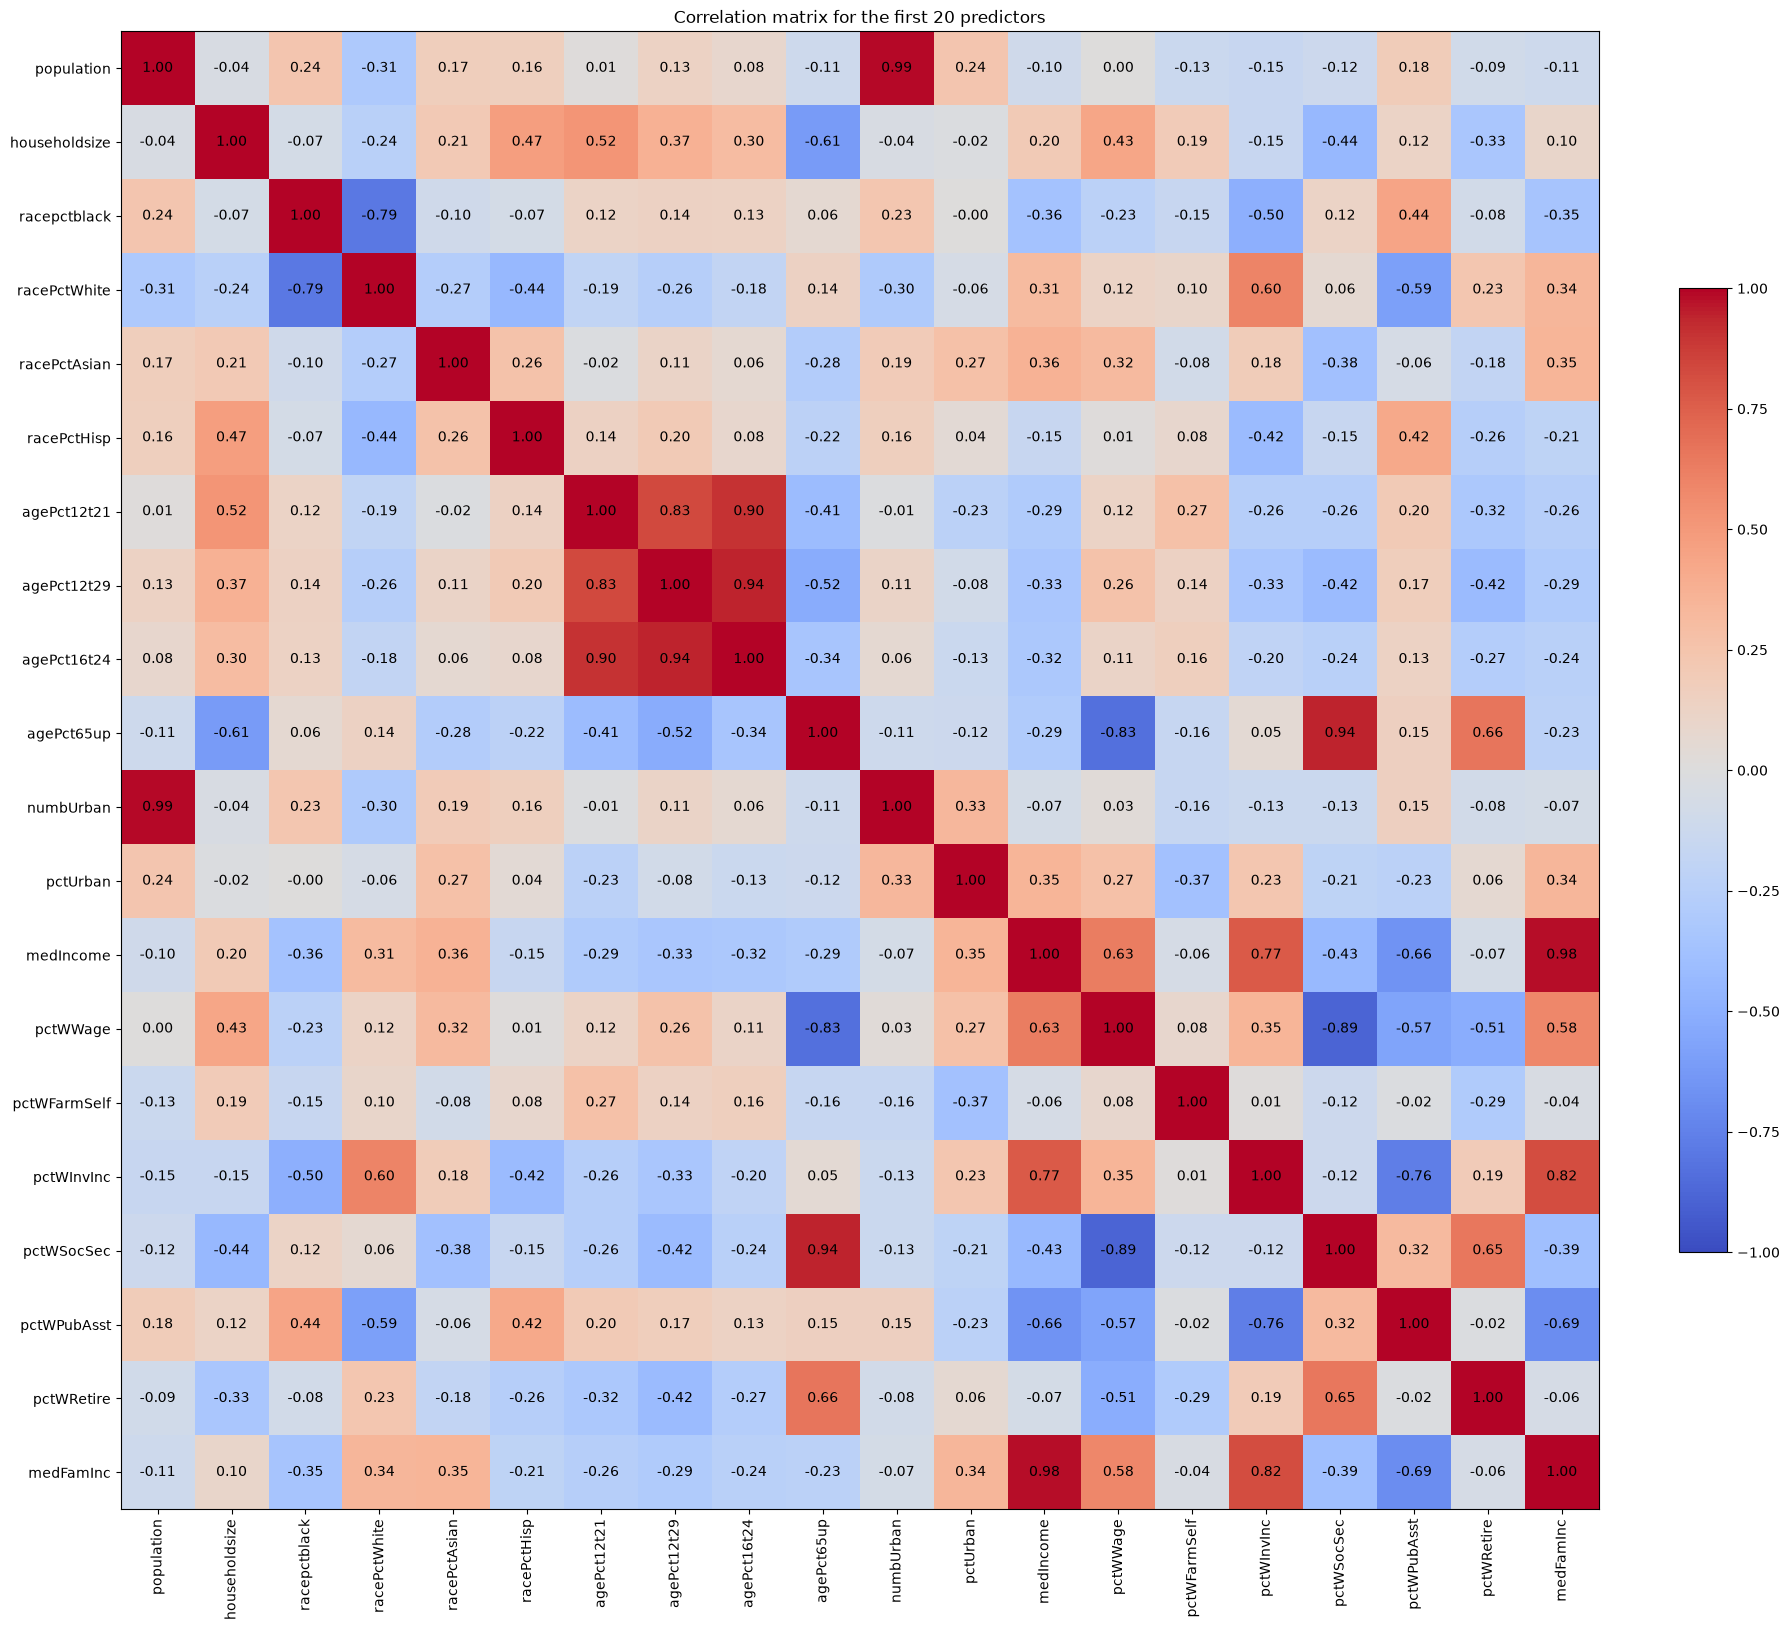

In [ ]:
def make_correlation_matrix(df, title="Correlation matrix"):
    corr = df.corr().round(2)
    fig, ax = plt.subplots(figsize=(18, 18))
    heatmap = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_title(title)
    ax.set_xticks(range(len(corr.columns)))
    ax.set_yticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticklabels(corr.columns)
    for i in range(len(corr.columns)):
        for j in range(len(corr.columns)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color="black")
    fig.colorbar(heatmap, ax=ax, fraction=0.03)
    plt.tight_layout()
    plt.show()

make_correlation_matrix(X_train_imp.iloc[:, :20], title="Correlation matrix for the first 20 predictors")



## (d) Coefficient of Variation (CV)

In [ ]:
cv_df = pd.DataFrame({
    "feature": X_train_imp.columns,
    "mean": X_train_imp.mean(axis=0),
    "std": X_train_imp.std(axis=0, ddof=1),
})
cv_df["cv"] = cv_df["std"] / cv_df["mean"]
cv_sorted = cv_df.sort_values("cv", ascending=False)
print("Top 15 features by coefficient of variation:")
print(cv_sorted.head(15).to_string(index=False))



Top 15 features by coefficient of variation:
            feature     mean      std       cv
      PctPolicAsian 0.016254 0.089838 5.527059
          NumStreet 0.022983 0.098665 4.292923
      NumInShelters 0.029599 0.102736 3.470952
           NumIlleg 0.037204 0.113806 3.058964
           NumImmig 0.030595 0.089541 2.926635
LemasPctOfficDrugUn 0.093304 0.238201 2.552946
        NumUnderPov 0.056849 0.133167 2.342443
       LemasSwornFT 0.028749 0.064629 2.248042
         population 0.058167 0.130359 2.241105
          numbUrban 0.064649 0.131784 2.038461
         HousVacant 0.076475 0.150538 1.968467
      PolicOperBudg 0.038074 0.062650 1.645508
           LandArea 0.064107 0.105482 1.645408
        racePctHisp 0.144963 0.233694 1.612091
PctNotSpeakEnglWell 0.151880 0.221231 1.456618


## (e) Top 11 features by CV: scatter plots and box plots

Selected features (11): ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'LemasSwornFT', 'population', 'numbUrban', 'HousVacant']


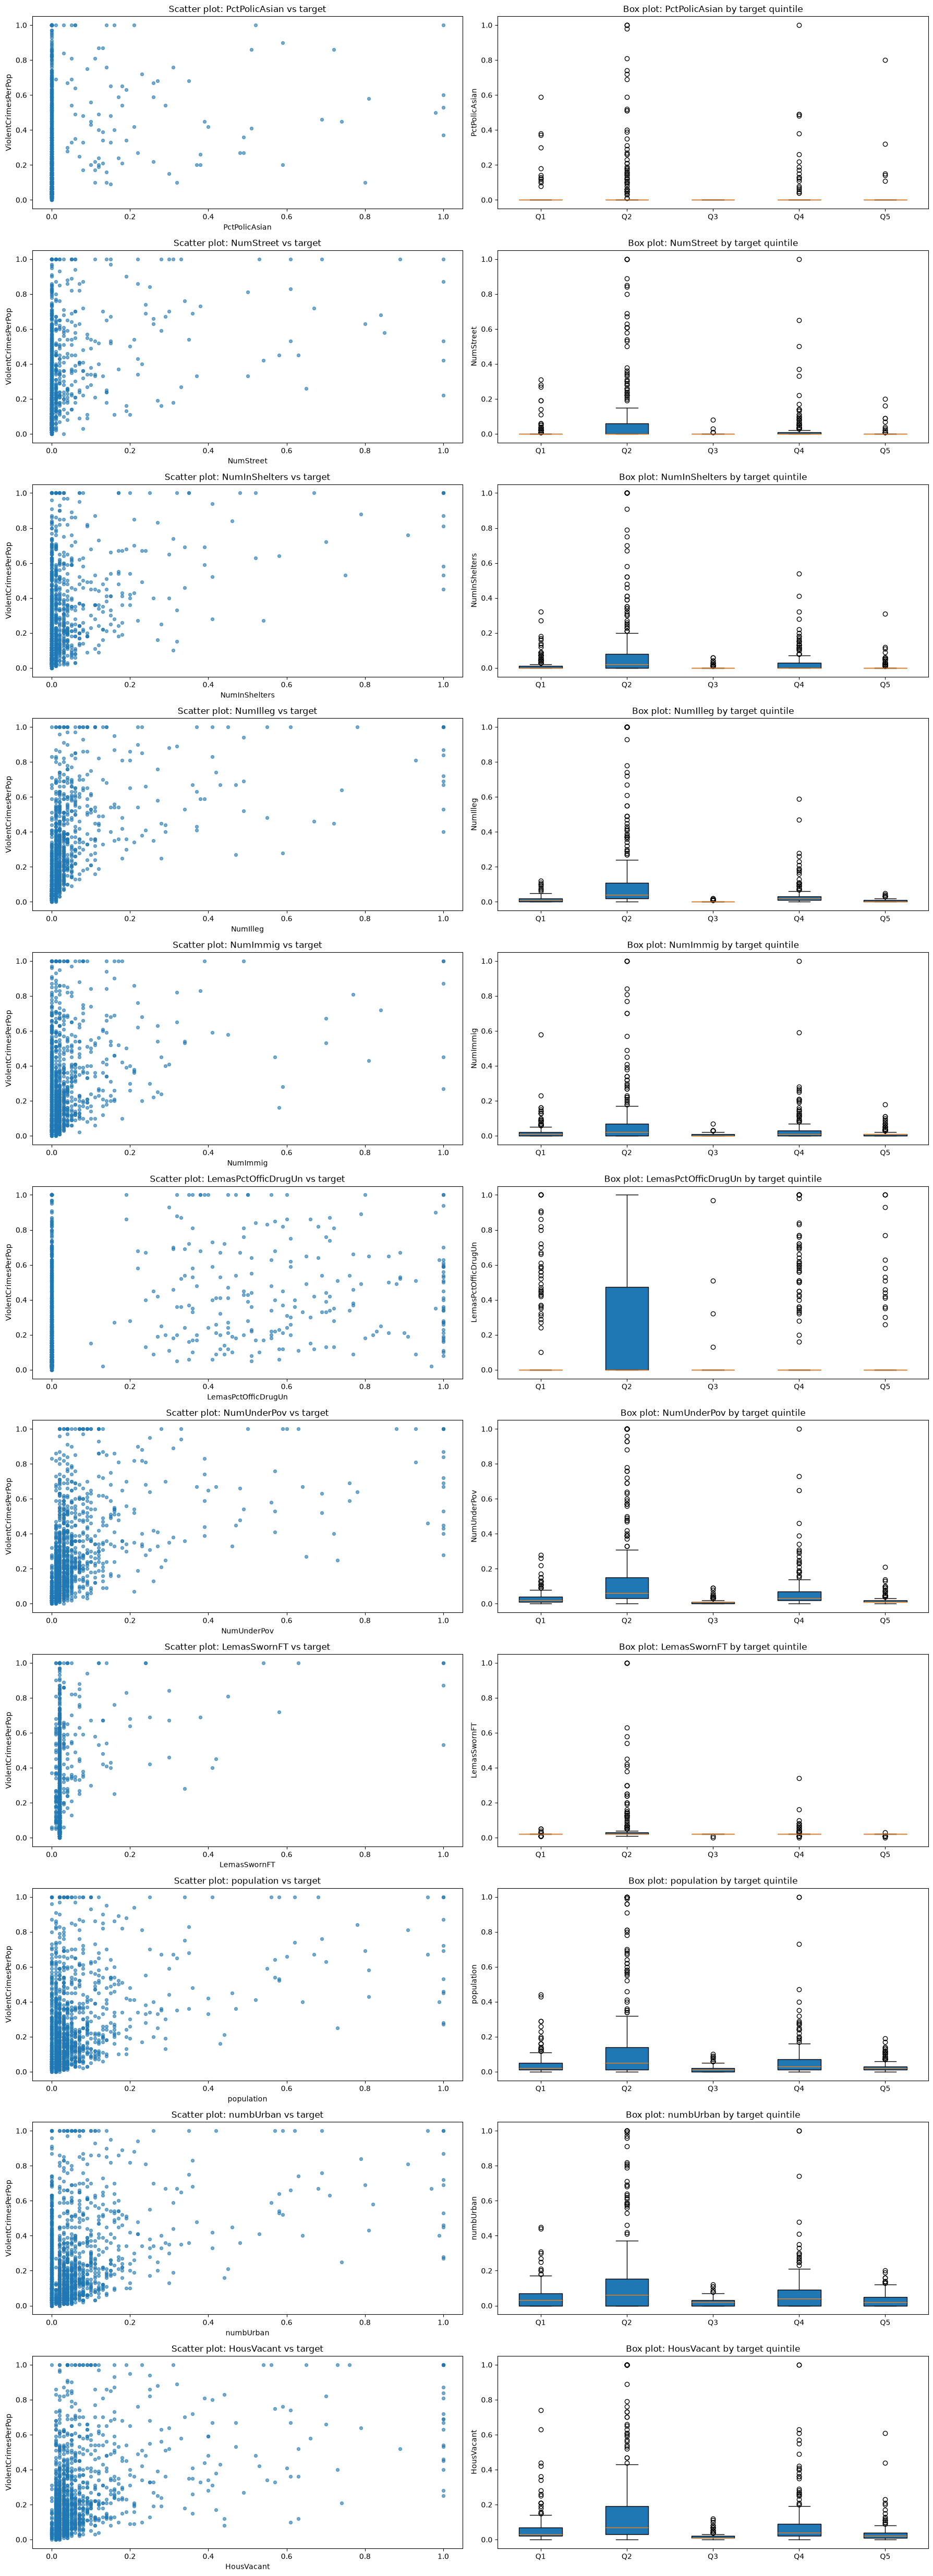

In [ ]:
n_top = int(np.floor(np.sqrt(128)))
selected = cv_sorted.head(n_top)["feature"].tolist()
print(f"Selected features ({n_top}): {selected}")

fig, axes = plt.subplots(n_top, 2, figsize=(18, 4.5 * n_top))
for idx, feature in enumerate(selected):
    ax1, ax2 = axes[idx]
    ax1.scatter(X_train_imp[feature], y_train, alpha=0.6, s=18)
    ax1.set_xlabel(feature)
    ax1.set_ylabel("ViolentCrimesPerPop")
    ax1.set_title(f"Scatter plot: {feature} vs target")

    bins = pd.qcut(y_train, q=5, duplicates="drop")
    grouped = [X_train_imp.loc[bins == b, feature].values for b in bins.unique()]
    ax2.boxplot(grouped, patch_artist=True)
    ax2.set_xticklabels([f"Q{i+1}" for i in range(len(grouped))])
    ax2.set_title(f"Box plot: {feature} by target quintile")
    ax2.set_ylabel(feature)

plt.tight_layout()
plt.show()



By eye, features such as PctIlleg, NumStreet, NumInShelters, NumIlleg, and NumImmig show the clearest separation in the scatter plots, suggesting stronger relationship with violent crime rate. However, the plots alone are not enough to establish causality or importance because the predictors are correlated and many variables are jointly informative.

## (f) Least squares regression

In [ ]:
least_squares = LinearRegression()
least_squares.fit(X_train_imp, y_train)
ls_pred = least_squares.predict(X_test_imp)
ls_mse = mean_squared_error(y_test, ls_pred)
ls_rmse = math.sqrt(ls_mse)
print(f"Least squares test MSE: {ls_mse:.6f}")
print(f"Least squares test RMSE: {ls_rmse:.6f}")



Least squares test MSE: 0.017966
Least squares test RMSE: 0.134038


## (g) Ridge regression with cross-validation

In [ ]:
a = np.logspace(-6, 6, 200)
ridge_cv = RidgeCV(alphas=a, cv=5)
ridge_cv.fit(X_train_imp, y_train)
ridge_pred = ridge_cv.predict(X_test_imp)
ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = math.sqrt(ridge_mse)
print(f"Chosen ridge lambda: {ridge_cv.alpha_:.6f}")
print(f"Ridge test MSE: {ridge_mse:.6f}")
print(f"Ridge test RMSE: {ridge_rmse:.6f}")



Chosen ridge lambda: 2.465811
Ridge test MSE: 0.017508
Ridge test RMSE: 0.132318


## (h) LASSO with and without standardization

In [ ]:
lasso_raw = LassoCV(alphas=np.logspace(-4, 1, 200), cv=5, max_iter=200000, random_state=552)
lasso_raw.fit(X_train_imp, y_train)
lasso_raw_pred = lasso_raw.predict(X_test_imp)
lasso_raw_mse = mean_squared_error(y_test, lasso_raw_pred)
lasso_raw_rmse = math.sqrt(lasso_raw_mse)
raw_selected = X_train_imp.columns[lasso_raw.coef_ != 0].tolist()
print(f"LASSO (raw features) lambda: {lasso_raw.alpha_:.8f}")
print(f"LASSO (raw) test MSE: {lasso_raw_mse:.6f}")
print(f"LASSO (raw) test RMSE: {lasso_raw_rmse:.6f}")
print(f"Number selected: {len(raw_selected)}")
print("Selected variables:")
print(raw_selected)

scaler = StandardScaler()
X_train_std = pd.DataFrame(scaler.fit_transform(X_train_imp), columns=X_train_imp.columns, index=X_train_imp.index)
X_test_std = pd.DataFrame(scaler.transform(X_test_imp), columns=X_test_imp.columns, index=X_test_imp.index)

lasso_std = LassoCV(alphas=np.logspace(-4, 1, 200), cv=5, max_iter=200000, random_state=552)
lasso_std.fit(X_train_std, y_train)
lasso_std_pred = lasso_std.predict(X_test_std)
lasso_std_mse = mean_squared_error(y_test, lasso_std_pred)
lasso_std_rmse = math.sqrt(lasso_std_mse)
std_selected = X_train_imp.columns[lasso_std.coef_ != 0].tolist()
print(f"LASSO (standardized) lambda: {lasso_std.alpha_:.8f}")
print(f"LASSO (standardized) test MSE: {lasso_std_mse:.6f}")
print(f"LASSO (standardized) test RMSE: {lasso_std_rmse:.6f}")
print(f"Number selected: {len(std_selected)}")
print("Selected variables:")
print(std_selected)
print("Comparison:")
print(f"Raw LASSO RMSE: {lasso_raw_rmse:.6f} | Standardized LASSO RMSE: {lasso_std_rmse:.6f}")



LASSO (raw features) lambda: 0.00012604
LASSO (raw) test MSE: 0.017615
LASSO (raw) test RMSE: 0.132723
Number selected: 74
Selected variables:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedO

## (i) Principal components regression (PCR)


In [ ]:
cv_errors = []
for m in range(1, min(X_train_imp.shape) + 1):
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=m)),
        ("reg", LinearRegression())
    ])
    scores = cross_val_score(pipe, X_train_imp, y_train, cv=5, scoring="neg_mean_squared_error")
    cv_errors.append((m, -scores.mean()))

best_m, best_cv_mse = min(cv_errors, key=lambda x: x[1])
print("PCR cross-validation results (M vs average CV MSE):")
print(pd.DataFrame(cv_errors, columns=["M", "CV_MSE"]).head(10).to_string(index=False))
print(f"Best M by CV: {best_m} with average CV MSE = {best_cv_mse:.6f}")

pcr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=best_m)),
    ("reg", LinearRegression())
])
pcr_pipe.fit(X_train_imp, y_train)
pcr_pred = pcr_pipe.predict(X_test_imp)
pcr_mse = mean_squared_error(y_test, pcr_pred)
pcr_rmse = math.sqrt(pcr_mse)
print(f"PCR test MSE: {pcr_mse:.6f}")
print(f"PCR test RMSE: {pcr_rmse:.6f}")



PCR cross-validation results (M vs average CV MSE):
 M   CV_MSE
 1 0.031308
 2 0.028392
 3 0.027984
 4 0.028014
 5 0.026223
 6 0.026299
 7 0.025948
 8 0.021997
 9 0.021228
10 0.021016
Best M by CV: 95 with average CV MSE = 0.019372
PCR test MSE: 0.018296
PCR test RMSE: 0.135264


## (j) Boosted regression tree with L1 regularization, using XGBoost

In [ ]:
param_grid = {"reg_alpha": [0, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10]}
model = xgb.XGBRegressor(
    objective="reg:squarederror",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=552,
    n_jobs=1,
)
search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="neg_mean_squared_error",
    cv=3,
    n_jobs=1,
)
search.fit(X_train_imp, y_train)

best_alpha = search.best_params_["reg_alpha"]
best_xgb = search.best_estimator_
boost_pred = best_xgb.predict(X_test_imp)
boost_mse = mean_squared_error(y_test, boost_pred)
boost_rmse = math.sqrt(boost_mse)

print(f"Best XGBoost lambda: {best_alpha}")
print(f"Boosted tree test MSE: {boost_mse:.6f}")
print(f"Boosted tree test RMSE: {boost_rmse:.6f}")
print("Top feature importances:")
importances = sorted(
    zip(X_train_imp.columns, best_xgb.feature_importances_),
    key=lambda x: x[1],
    reverse=True,
)[:10]
print(importances)



Best XGBoost lambda: 0.001
Boosted tree test MSE: 0.015788
Boosted tree test RMSE: 0.125649
Top feature importances:
[('PctIlleg', np.float32(0.18308508)), ('PctKids2Par', np.float32(0.1559649)), ('racePctWhite', np.float32(0.03321036)), ('PctFam2Par', np.float32(0.03274705)), ('NumIlleg', np.float32(0.02577225)), ('PctPersDenseHous', np.float32(0.020353755)), ('NumStreet', np.float32(0.017387135)), ('HousVacant', np.float32(0.014676573)), ('FemalePctDiv', np.float32(0.012911966)), ('PctHousLess3BR', np.float32(0.012769202))]


## Summary

In [ ]:
summary = pd.DataFrame({
    "Model": [
        "Least squares",
        "Ridge",
        "LASSO (raw)",
        "LASSO (standardized)",
        "PCR",
        "Boosted tree"
    ],
    "Test MSE": [
        ls_mse,
        ridge_mse,
        lasso_raw_mse,
        lasso_std_mse,
        pcr_mse,
        boost_mse,
    ],
    "Test RMSE": [
        ls_rmse,
        ridge_rmse,
        lasso_raw_rmse,
        lasso_std_rmse,
        pcr_rmse,
        boost_rmse,
    ]
})
print(summary.to_string(index=False))



               Model  Test MSE  Test RMSE
       Least squares  0.017966   0.134038
               Ridge  0.017508   0.132318
         LASSO (raw)  0.017615   0.132723
LASSO (standardized)  0.017672   0.132936
                 PCR  0.018296   0.135264
        Boosted tree  0.015788   0.125649
